In [ ]:
import argparse
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer

In [ ]:
TARGET = "Yield_kg_per_ha"

In [ ]:
CATEGORICAL_FEATURES = ["State Name", "Dist Name", "Crop"]
NUMERIC_FEATURES = [
    "Year",
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day",
]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES


In [ ]:
def log1p_safe(y):
    return np.log1p(np.clip(y, a_min=0, a_max=None))


def expm1_safe(y):
    return np.maximum(np.expm1(y), 0)

In [ ]:
def make_pipeline(model):
    categorical_pipe = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]
    )
    numeric_pipe = Pipeline(
        steps=[("imputer", SimpleImputer(strategy="median"))]
    )
    preprocessor = ColumnTransformer(
        transformers=[
            ("cat", categorical_pipe, CATEGORICAL_FEATURES),
            ("num", numeric_pipe, NUMERIC_FEATURES),
        ],
        remainder="drop",
    )
    return Pipeline(
        steps=[
            ("preprocess", preprocessor),
            ("log_target_transform", FunctionTransformer(log1p_safe, inverse_func=expm1_safe)),
            ("model", model),
        ]
    )

In [ ]:
def main():
    df = pd.read_csv("/content/Custom_Crops_yield_Historical_Dataset.csv")
    df.columns = df.columns.str.strip()

    print("Dataset loaded successfully!")
    print(df.shape)
    print(df.head())
    df.columns = df.columns.str.strip()

    if TARGET not in df.columns:
        raise ValueError(
            f"Target '{TARGET}' not found. Columns in file: {df.columns.tolist()}"
        )

    missing_features = [c for c in FEATURES if c not in df.columns]
    if missing_features:
        raise ValueError(
            "Expected columns are missing: "
            + ", ".join(missing_features)
            + "\nEdit FEATURES above to match your CSV."
        )

In [ ]:
# Convert numeric columns
for col in NUMERIC_FEATURES + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove missing target values
df = df.dropna(subset=[TARGET])

# Remove negative yields
df = df[df[TARGET] >= 0].copy()

# Remove duplicates
df = df.drop_duplicates()

# Clean categorical columns
for col in CATEGORICAL_FEATURES:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .fillna("Unknown")
        .replace("", "Unknown")
        .astype(str)
    )

# Prepare features and target
X = df[FEATURES].copy()
y = df[TARGET].astype(float).copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

NameError: name 'df' is not defined

In [ ]:
import os
import pandas as pd
import numpy as np

files = [
    f for f in os.listdir("/content")
    if f.endswith(".csv") and f.startswith("Custom_Crops_yield_Historical_")
]

print("Files found:", files)

if not files:
    raise FileNotFoundError("Please upload your Kaggle CSV file.")

df = pd.read_csv("/content/" + files[0])
df.columns = df.columns.str.strip()

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Files found: ['Custom_Crops_yield_Historical_Dataset.csv']

Dataset loaded successfully!
Shape: (50765, 20)

Columns:
['Dist Code', 'Year', 'State Code', 'State Name', 'Dist Name', 'Crop', 'Area_ha', 'Yield_kg_per_ha', 'N_req_kg_per_ha', 'P_req_kg_per_ha', 'K_req_kg_per_ha', 'Total_N_kg', 'Total_P_kg', 'Total_K_kg', 'Temperature_C', 'Humidity_%', 'pH', 'Rainfall_mm', 'Wind_Speed_m_s', 'Solar_Radiation_MJ_m2_day']


In [ ]:
print("df exists:", "df" in globals())
print("Rows:", len(df))

df exists: True
Rows: 50765


In [ ]:
for col in NUMERIC_FEATURES + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [ ]:
print(df.columns.tolist())

['Dist Code', 'Year', 'State Code', 'State Name', 'Dist Name', 'Crop', 'Area_ha', 'Yield_kg_per_ha', 'N_req_kg_per_ha', 'P_req_kg_per_ha', 'K_req_kg_per_ha', 'Total_N_kg', 'Total_P_kg', 'Total_K_kg', 'Temperature_C', 'Humidity_%', 'pH', 'Rainfall_mm', 'Wind_Speed_m_s', 'Solar_Radiation_MJ_m2_day']


In [ ]:
TARGET = "Yield_kg_per_ha"

CATEGORICAL_FEATURES = [
    "State Name",
    "Dist Name",
    "Crop"
]

NUMERIC_FEATURES = [
    "Year",
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

print("Features defined successfully!")

Features defined successfully!


In [ ]:
# Convert numeric columns
for col in NUMERIC_FEATURES + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing target values
df = df.dropna(subset=[TARGET])

# Remove negative yield values
df = df[df[TARGET] >= 0].copy()

# Remove duplicate rows
df = df.drop_duplicates()

# Clean categorical columns
for col in CATEGORICAL_FEATURES:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .fillna("Unknown")
        .replace("", "Unknown")
        .astype(str)
    )

# Create X and y
X = df[FEATURES].copy()
y = df[TARGET].astype(float).copy()

print("Cleaning completed!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Cleaning completed!
Features shape: (50765, 10)
Target shape: (50765,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 40612
Testing samples: 10153


In [ ]:
print(X_train.head())
print(y_train.head())

           State Name      Dist Name    Crop  Year  Temperature_C  Humidity_%  \
33299   Uttar Pradesh           Etah  cotton  1981             28          65   
911      Chhattisgarh        Surguja    rice  1995             25          80   
2772   Madhya Pradesh           Rewa   maize  1973             22          70   
41078           Assam  Karbi Anglong    rice  2009             25          80   
2351   Madhya Pradesh      Tikamgarh    rice  1989             25          80   

        pH  Rainfall_mm  Wind_Speed_m_s  Solar_Radiation_MJ_m2_day  
33299  6.0          700             3.0                         22  
911    6.5         1200             2.0                         18  
2772   6.0          800             2.5                         20  
41078  6.5         1200             2.0                         18  
2351   6.5         1200             2.0                         18  
33299     250.00
911       880.39
2772      692.31
41078    1978.16
2351      476.67
Name: Yield_kg

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Process categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Process numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
    ("num", numeric_pipeline, NUMERIC_FEATURES)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Preprocessing completed!
Training shape: (40612, 342)
Testing shape: (10153, 342)


In [ ]:
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
import numpy as np

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():
    model.fit(X_train_processed, np.log1p(y_train))

    predictions = np.expm1(model.predict(X_test_processed))
    predictions = np.maximum(predictions, 0)

    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(f"\n{name}")
    print(f"MAE:  {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²:   {r2:.4f}")


Random Forest
MAE:  196.06
RMSE: 341.82
R²:   0.8737

Extra Trees
MAE:  191.02
RMSE: 336.78
R²:   0.8773


In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

extra_model = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
extra_model.fit(
    X_train_processed,
    np.log1p(y_train)
)

# Make predictions
extra_predictions = np.expm1(
    extra_model.predict(X_test_processed)
)

extra_predictions = np.maximum(extra_predictions, 0)

# Evaluate
mae = mean_absolute_error(y_test, extra_predictions)
rmse = np.sqrt(mean_squared_error(y_test, extra_predictions))
r2 = r2_score(y_test, extra_predictions)

print("Extra Trees Results")
print("-------------------")
print(f"MAE:  {mae:.2f} kg/ha")
print(f"RMSE: {rmse:.2f} kg/ha")
print(f"R²:   {r2:.4f}")

Extra Trees Results
-------------------
MAE:  190.77 kg/ha
RMSE: 336.41 kg/ha
R²:   0.8776


In [ ]:
import joblib
import numpy as np
from sklearn.pipeline import Pipeline

# Combine preprocessing and the trained Extra Trees model
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", extra_model)
])

# Save the model and its configuration
artifact = {
    "pipeline": final_model,
    "features": FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "target": TARGET,
    "target_transform": "log1p",
    "model_name": "Extra Trees"
}

joblib.dump(artifact, "/content/crop_yield_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import pandas as pd
import numpy as np

comparison = pd.DataFrame({
    "Actual Yield": y_test.values,
    "Predicted Yield": extra_predictions
})

comparison["Absolute Error"] = (
    comparison["Actual Yield"] - comparison["Predicted Yield"]
).abs()

print(comparison.head(10).round(2))

   Actual Yield  Predicted Yield  Absolute Error
0       2157.01          2111.23           45.78
1         90.91           184.93           94.02
2       2030.45          1829.48          200.97
3        461.54           579.30          117.76
4       1542.37          1561.61           19.24
5       3272.85          2394.83          878.02
6       1988.89          2222.31          233.42
7        529.27          1091.61          562.34
8        250.00           380.94          130.94
9       1698.41          1444.13          254.28


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Compare actual and predicted values
error_analysis = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": extra_predictions
})

error_analysis["Absolute_Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
).abs()

error_analysis["Percentage_Error"] = (
    error_analysis["Absolute_Error"]
    / error_analysis["Actual"].replace(0, np.nan)
) * 100

print("Overall MAE:", mean_absolute_error(
    error_analysis["Actual"],
    error_analysis["Predicted"]
))

print("Overall RMSE:", np.sqrt(mean_squared_error(
    error_analysis["Actual"],
    error_analysis["Predicted"]
)))

print("\nLargest prediction errors:")
print(
    error_analysis.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(10).round(2)
)

Overall MAE: 190.77355554683268
Overall RMSE: 336.4123334061201

Largest prediction errors:
       Actual  Predicted  Absolute_Error  Percentage_Error
6571  8171.22    3003.42         5167.80             63.24
9995  8000.00    3640.97         4359.03             54.49
7484  4833.33     537.10         4296.23             88.89
3943   666.67    4347.55         3680.88            552.13
9621  6247.74    2631.30         3616.44             57.88
4486  5000.00    1446.07         3553.93             71.08
9578  3663.82    7165.64         3501.82             95.58
7196  4286.44     873.89         3412.55             79.61
6552  4512.76    1146.11         3366.65             74.60
8353  5025.64    1664.91         3360.73             66.87


In [ ]:
crop_analysis = pd.DataFrame({
    "Crop": X_test["Crop"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": extra_predictions
})

crop_analysis["Absolute_Error"] = (
    crop_analysis["Actual"] - crop_analysis["Predicted"]
).abs()

crop_results = crop_analysis.groupby("Crop").apply(
    lambda group: pd.Series({
        "Records": len(group),
        "MAE": mean_absolute_error(
            group["Actual"],
            group["Predicted"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group["Actual"],
            group["Predicted"]
        )),
        "R2": r2_score(
            group["Actual"],
            group["Predicted"]
        ) if len(group) > 1 else np.nan
    }),
    include_groups=False
)

print(crop_results.round(2))

          Records     MAE    RMSE    R2
Crop                                   
chickpea   2807.0  134.46  214.72  0.61
cotton     1572.0   63.84  154.01  0.63
maize      2797.0  312.71  516.66  0.79
rice       2977.0  196.34  281.40  0.90


In [ ]:
extra_model.fit(
    X_train_processed,
    np.log1p(y_train)
)

ExtraTreesRegressor(min_samples_leaf=2, n_estimators=300, n_jobs=-1,
                    random_state=42)

In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Train on original yield values
extra_model_original = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

extra_model_original.fit(
    X_train_processed,
    y_train
)

# Predict crop yield
predictions_original = extra_model_original.predict(
    X_test_processed
)

predictions_original = np.maximum(
    predictions_original,
    0
)

# Evaluate the model
mae = mean_absolute_error(
    y_test,
    predictions_original
)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions_original)
)

r2 = r2_score(
    y_test,
    predictions_original
)

print("Extra Trees - Original Target")
print("------------------------------")
print(f"MAE:  {mae:.2f} kg/ha")
print(f"RMSE: {rmse:.2f} kg/ha")
print(f"R²:   {r2:.4f}")

Extra Trees - Original Target
------------------------------
MAE:  192.40 kg/ha
RMSE: 338.61 kg/ha
R²:   0.8760


In [ ]:
crop_analysis_original = pd.DataFrame({
    "Crop": X_test["Crop"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": predictions_original
})

results_by_crop = []

for crop, group in crop_analysis_original.groupby("Crop"):
    results_by_crop.append({
        "Crop": crop,
        "Records": len(group),
        "MAE": mean_absolute_error(
            group["Actual"],
            group["Predicted"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group["Actual"],
            group["Predicted"]
        )),
        "R2": r2_score(
            group["Actual"],
            group["Predicted"]
        )
    })

print(
    pd.DataFrame(results_by_crop)
    .round(2)
    .to_string(index=False)
)

    Crop  Records    MAE   RMSE   R2
chickpea     2807 139.98 248.06 0.48
  cotton     1572  67.34 158.82 0.60
   maize     2797 308.02 501.85 0.81
    rice     2977 199.24 288.19 0.89


In [ ]:
import pandas as pd
import numpy as np

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Combine features and target
data = X.copy()
data[TARGET] = y

# Split by year: earlier years for training,
# later years for testing
split_year = data["Year"].quantile(0.80)

train_data = data[data["Year"] < split_year].copy()
test_data = data[data["Year"] >= split_year].copy()

X_train_time = train_data[FEATURES]
y_train_time = train_data[TARGET]

X_test_time = test_data[FEATURES]
y_test_time = test_data[TARGET]

print("Training years:", train_data["Year"].min(),
      "to", train_data["Year"].max())

print("Testing years:", test_data["Year"].min(),
      "to", test_data["Year"].max())

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

# Fit preprocessing only on training data
time_preprocessor = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        CATEGORICAL_FEATURES
    ),
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        NUMERIC_FEATURES
    )
])

X_train_time_processed = time_preprocessor.fit_transform(
    X_train_time
)

X_test_time_processed = time_preprocessor.transform(
    X_test_time
)

# Train the model on the original target
time_model = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

time_model.fit(X_train_time_processed, y_train_time)

time_predictions = np.maximum(
    time_model.predict(X_test_time_processed),
    0
)

print("\nTime-based evaluation")
print("MAE:", round(mean_absolute_error(
    y_test_time, time_predictions
), 2))

print("RMSE:", round(np.sqrt(mean_squared_error(
    y_test_time, time_predictions
)), 2))

print("R²:", round(r2_score(
    y_test_time, time_predictions
), 4))

Training years: 1966 to 2006
Testing years: 2007 to 2017
Training rows: 40058
Testing rows: 10707

Time-based evaluation
MAE: 445.77
RMSE: 967.14
R²: 0.5511


In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

results = []

for target_transform in ["original", "log"]:

    model = ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    # Train on earlier years
    if target_transform == "log":
        model.fit(
            X_train_time_processed,
            np.log1p(y_train_time)
        )

        predictions = np.expm1(
            model.predict(X_test_time_processed)
        )

    else:
        model.fit(
            X_train_time_processed,
            y_train_time
        )

        predictions = model.predict(
            X_test_time_processed
        )

    predictions = np.maximum(predictions, 0)

    results.append({
        "Target Transformation": target_transform,
        "MAE": mean_absolute_error(
            y_test_time, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_time, predictions)
        ),
        "R2": r2_score(
            y_test_time, predictions
        )
    })

print(pd.DataFrame(results).round(3).to_string(index=False))

Target Transformation     MAE    RMSE    R2
             original 445.771 967.143 0.551
                  log 464.731 996.229 0.524


In [ ]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

crop_results = pd.DataFrame({
    "Crop": X_test_time["Crop"].to_numpy(),
    "Actual": y_test_time.to_numpy(),
    "Predicted": time_predictions
})

results_by_crop = []

for crop, group in crop_results.groupby("Crop"):

    results_by_crop.append({
        "Crop": crop,
        "Records": len(group),

        "MAE": mean_absolute_error(
            group["Actual"],
            group["Predicted"]
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                group["Actual"],
                group["Predicted"]
            )
        ),

        "R2": r2_score(
            group["Actual"],
            group["Predicted"]
        ) if len(group) > 1 else np.nan
    })

crop_metrics = pd.DataFrame(results_by_crop)

print(crop_metrics.round(2).to_string(index=False))

    Crop  Records    MAE    RMSE   R2
chickpea     2924 270.30 1254.86 0.02
  cotton     1598 162.21  290.92 0.03
   maize     3089 786.16 1174.99 0.46
    rice     3096 418.24  571.36 0.65


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create training and testing tables
train_eval = X_train_time.copy()
train_eval["Yield"] = y_train_time.values

test_eval = X_test_time.copy()
test_eval["Actual"] = y_test_time.values

# Calculate average yield for each crop using training data only
crop_mean = train_eval.groupby("Crop")["Yield"].mean()

# Predict using the training-set average for each crop
baseline_predictions = (
    test_eval["Crop"]
    .map(crop_mean)
    .fillna(y_train_time.mean())
    .to_numpy()
)

# Evaluate the baseline
baseline_mae = mean_absolute_error(
    y_test_time,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test_time, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test_time,
    baseline_predictions
)

print("Crop Mean Baseline")
print("------------------")
print(f"MAE:  {baseline_mae:.2f} kg/ha")
print(f"RMSE: {baseline_rmse:.2f} kg/ha")
print(f"R²:   {baseline_r2:.4f}")

Crop Mean Baseline
------------------
MAE:  784.32 kg/ha
RMSE: 1407.08 kg/ha
R²:   0.0499


In [ ]:
import pandas as pd

train_summary = (
    train_eval.groupby("Crop")["Yield"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

test_summary = (
    test_eval.groupby("Crop")["Actual"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print("TRAINING YIELD DISTRIBUTION")
print(train_summary)

print("\nTESTING YIELD DISTRIBUTION")
print(test_summary)

TRAINING YIELD DISTRIBUTION
          count     mean   median   min      max
Crop                                            
chickpea  10923   666.98   625.00  3.08  4833.33
cotton     6206   223.75   189.98  6.47  5000.00
maize     11047  1376.08  1153.85  3.35  9524.14
rice      11882  1445.33  1272.42  9.12  5542.32

TESTING YIELD DISTRIBUTION
          count     mean   median    min       max
Crop                                              
chickpea   2924   984.72   930.24  76.92  58363.64
cotton     1598   388.46   352.78   0.28   2857.74
maize      3089  2428.43  2016.13  41.91  21428.57
rice       3096  2205.26  2204.75  90.00   5653.83


In [ ]:
# Display the highest chickpea yields in the full dataset

chickpea_extremes = data[
    data["Crop"].str.lower() == "chickpea"
].sort_values(
    TARGET,
    ascending=False
)

print(
    chickpea_extremes[
        [
            "Year",
            "State Name",
            "Dist Name",
            "Crop",
            TARGET,
            "Temperature_C",
            "Rainfall_mm",
            "pH"
        ]
    ].head(10).to_string(index=False)
)

 Year     State Name     Dist Name     Crop  Yield_kg_per_ha  Temperature_C  Rainfall_mm  pH
 2007          Bihar   Muzaffarpur chickpea         58363.64             20          600 6.5
 2007          Bihar       Saharsa chickpea         32000.00             20          600 6.5
 2017        Haryana        Ambala chickpea          5000.00             20          600 6.5
 1968      Rajasthan         Sikar chickpea          4833.33             20          600 6.5
 2016        Haryana        Rohtak chickpea          4000.00             20          600 6.5
 1994      Rajasthan        Sirohi chickpea          3140.04             20          600 6.5
 1975        Haryana       Gurgaon chickpea          3065.81             20          600 6.5
 2005 Andhra Pradesh East Godavari chickpea          3000.00             20          600 6.5
 2012 Madhya Pradesh    Chhindwara chickpea          2828.83             20          600 6.5
 2011 Madhya Pradesh    Chhindwara chickpea          2740.74          

In [ ]:
for crop in data["Crop"].unique():

    print(f"\n{'=' * 50}")
    print("Crop:", crop)
    print("=" * 50)

    crop_data = data[data["Crop"] == crop]

    print(
        crop_data.nlargest(10, TARGET)[
            [
                "Year",
                "State Name",
                "Dist Name",
                "Crop",
                TARGET
            ]
        ].to_string(index=False)
    )


Crop: rice
 Year     State Name               Dist Name Crop  Yield_kg_per_ha
 2013     Tamil Nadu            Thirunelveli rice          5653.83
 1971          Bihar                 Saharsa rice          5542.32
 2011     Tamil Nadu             Kanyakumari rice          5421.78
 2017 Madhya Pradesh                    Rewa rice          5159.93
 2014     Tamil Nadu                   Salem rice          5129.68
 2014     Tamil Nadu            Thirunelveli rice          5117.01
 2013     Tamil Nadu Tiruchirapalli / Trichy rice          5094.65
 2014     Tamil Nadu             Kanyakumari rice          5078.91
 2017         Punjab                 Sangrur rice          5047.54
 2014     Tamil Nadu            The Nilgiris rice          5000.00

Crop: maize
 Year     State Name                      Dist Name  Crop  Yield_kg_per_ha
 2016        Haryana                         Rohtak maize         21428.57
 2017 Andhra Pradesh                     Kadapa YSR maize         11368.52
 2010 Andhra 

In [ ]:
# Count unusually high yields for each crop
for crop in data["Crop"].unique():

    crop_data = data[data["Crop"] == crop]

    print(f"\nCrop: {crop}")

    print(
        "Yield above 10,000 kg/ha:",
        (crop_data[TARGET] > 10000).sum()
    )

    print(
        "Yield above 5,000 kg/ha:",
        (crop_data[TARGET] > 5000).sum()
    )


Crop: rice
Yield above 10,000 kg/ha: 0
Yield above 5,000 kg/ha: 9

Crop: maize
Yield above 10,000 kg/ha: 4
Yield above 5,000 kg/ha: 297

Crop: chickpea
Yield above 10,000 kg/ha: 2
Yield above 5,000 kg/ha: 2

Crop: cotton
Yield above 10,000 kg/ha: 0
Yield above 5,000 kg/ha: 0


In [ ]:
environment_columns = [
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

print("Unique values in each feature:")
print(data[environment_columns].nunique())

print("\nFeature summary:")
print(data[environment_columns].describe().round(2))

Unique values in each feature:
Temperature_C                4
Humidity_%                   4
pH                           2
Rainfall_mm                  4
Wind_Speed_m_s               4
Solar_Radiation_MJ_m2_day    4
dtype: int64

Feature summary:
       Temperature_C  Humidity_%        pH  Rainfall_mm  Wind_Speed_m_s  \
count       50765.00    50765.00  50765.00     50765.00        50765.00   
mean           23.26       69.45      6.28       848.09            2.16   
std             2.77        7.77      0.25       239.47            0.52   
min            20.00       60.00      6.00       600.00            1.50   
25%            20.00       60.00      6.00       600.00            1.50   
50%            22.00       70.00      6.50       800.00            2.00   
75%            25.00       80.00      6.50      1200.00            2.50   
max            28.00       80.00      6.50      1200.00            3.00   

       Solar_Radiation_MJ_m2_day  
count                   50765.00  
mean  

In [ ]:
# Check environmental variation by year

environment_columns = [
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

print("Environmental feature variation by year:\n")

for col in environment_columns:
    print(f"\n{col}")

    print(
        data.groupby("Year")[col]
        .nunique()
        .describe()
        .round(2)
    )

Environmental feature variation by year:


Temperature_C
count    52.0
mean      4.0
std       0.0
min       4.0
25%       4.0
50%       4.0
75%       4.0
max       4.0
Name: Temperature_C, dtype: float64

Humidity_%
count    52.0
mean      4.0
std       0.0
min       4.0
25%       4.0
50%       4.0
75%       4.0
max       4.0
Name: Humidity_%, dtype: float64

pH
count    52.0
mean      2.0
std       0.0
min       2.0
25%       2.0
50%       2.0
75%       2.0
max       2.0
Name: pH, dtype: float64

Rainfall_mm
count    52.0
mean      4.0
std       0.0
min       4.0
25%       4.0
50%       4.0
75%       4.0
max       4.0
Name: Rainfall_mm, dtype: float64

Wind_Speed_m_s
count    52.0
mean      4.0
std       0.0
min       4.0
25%       4.0
50%       4.0
75%       4.0
max       4.0
Name: Wind_Speed_m_s, dtype: float64

Solar_Radiation_MJ_m2_day
count    52.0
mean      4.0
std       0.0
min       4.0
25%       4.0
50%       4.0
75%       4.0
max       4.0
Name: Solar_Radiation_MJ_m2_day, d

In [ ]:
environment_columns = [
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

for col in environment_columns:
    print(f"\nFeature: {col}")

    print(
        data.groupby("Year")[col]
        .nunique()
        .head(10)
    )

    print(
        "Unique values in entire dataset:",
        data[col].nunique()
    )


Feature: Temperature_C
Year
1966    4
1967    4
1968    4
1969    4
1970    4
1971    4
1972    4
1973    4
1974    4
1975    4
Name: Temperature_C, dtype: int64
Unique values in entire dataset: 4

Feature: Humidity_%
Year
1966    4
1967    4
1968    4
1969    4
1970    4
1971    4
1972    4
1973    4
1974    4
1975    4
Name: Humidity_%, dtype: int64
Unique values in entire dataset: 4

Feature: pH
Year
1966    2
1967    2
1968    2
1969    2
1970    2
1971    2
1972    2
1973    2
1974    2
1975    2
Name: pH, dtype: int64
Unique values in entire dataset: 2

Feature: Rainfall_mm
Year
1966    4
1967    4
1968    4
1969    4
1970    4
1971    4
1972    4
1973    4
1974    4
1975    4
Name: Rainfall_mm, dtype: int64
Unique values in entire dataset: 4

Feature: Wind_Speed_m_s
Year
1966    4
1967    4
1968    4
1969    4
1970    4
1971    4
1972    4
1973    4
1974    4
1975    4
Name: Wind_Speed_m_s, dtype: int64
Unique values in entire dataset: 4

Feature: Solar_Radiation_MJ_m2_day
Year

In [ ]:
# Check whether environmental values are repeated across districts

environment_columns = [
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

for col in environment_columns:
    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print("=" * 50)

    print("Unique values:", sorted(data[col].dropna().unique()))

    print("\nMost frequent values:")
    print(data[col].value_counts().head(10))

    print("\nNumber of distinct values by crop:")
    print(data.groupby("Crop")[col].nunique())


Feature: Temperature_C
Unique values: [np.int64(20), np.int64(22), np.int64(25), np.int64(28)]

Most frequent values:
Temperature_C
25    14978
22    14136
20    13847
28     7804
Name: count, dtype: int64

Number of distinct values by crop:
Crop
chickpea    1
cotton      1
maize       1
rice        1
Name: Temperature_C, dtype: int64

Feature: Humidity_%
Unique values: [np.int64(60), np.int64(65), np.int64(70), np.int64(80)]

Most frequent values:
Humidity_%
80    14978
70    14136
60    13847
65     7804
Name: count, dtype: int64

Number of distinct values by crop:
Crop
chickpea    1
cotton      1
maize       1
rice        1
Name: Humidity_%, dtype: int64

Feature: pH
Unique values: [np.float64(6.0), np.float64(6.5)]

Most frequent values:
pH
6.5    28825
6.0    21940
Name: count, dtype: int64

Number of distinct values by crop:
Crop
chickpea    1
cotton      1
maize       1
rice        1
Name: pH, dtype: int64

Feature: Rainfall_mm
Unique values: [np.int64(600), np.int64(700), np.i

In [ ]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

environment_columns = [
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

# Model 1: Use all existing features
# Model 2: Exclude environmental features
feature_sets = {
    "All features": FEATURES,
    "Without environmental features": [
        col for col in FEATURES
        if col not in environment_columns
    ]
}

results = []

for name, feature_cols in feature_sets.items():

    categorical_cols = [
        col for col in CATEGORICAL_FEATURES
        if col in feature_cols
    ]

    numeric_cols = [
        col for col in NUMERIC_FEATURES
        if col in feature_cols
    ]

    preprocessor_test = ColumnTransformer(
        transformers=[
            (
                "cat",
                Pipeline([
                    (
                        "imputer",
                        SimpleImputer(strategy="most_frequent")
                    ),
                    (
                        "encoder",
                        OneHotEncoder(handle_unknown="ignore")
                    )
                ]),
                categorical_cols
            ),
            (
                "num",
                Pipeline([
                    (
                        "imputer",
                        SimpleImputer(strategy="median")
                    )
                ]),
                numeric_cols
            )
        ]
    )

    X_train = X_train_time[feature_cols]
    X_test = X_test_time[feature_cols]

    X_train_processed = preprocessor_test.fit_transform(X_train)
    X_test_processed = preprocessor_test.transform(X_test)

    model = ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_processed, y_train_time)

    predictions = np.maximum(
        model.predict(X_test_processed),
        0
    )

    results.append({
        "Feature Set": name,
        "MAE": mean_absolute_error(
            y_test_time, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_time, predictions)
        ),
        "R2": r2_score(
            y_test_time, predictions
        )
    })

print(pd.DataFrame(results).round(3).to_string(index=False))

                   Feature Set     MAE    RMSE    R2
                  All features 445.771 967.143 0.551
Without environmental features 445.762 966.834 0.551


In [ ]:
# Target column
TARGET = "Yield_kg_per_ha"

# Categorical features
CATEGORICAL_FEATURES = [
    "Crop",
    "State Name",
    "Dist Name"
]

# Numeric features
NUMERIC_FEATURES = [
    "Year",
    "Area_ha",
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

# Combine all features
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

print("Features defined successfully!")
print(FEATURES)

Features defined successfully!
['Crop', 'State Name', 'Dist Name', 'Year', 'Area_ha', 'Temperature_C', 'Humidity_%', 'pH', 'Rainfall_mm', 'Wind_Speed_m_s', 'Solar_Radiation_MJ_m2_day']


In [ ]:
print("Dataset columns:")
print(data.columns.tolist())

missing_columns = [
    col for col in FEATURES + [TARGET]
    if col not in data.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required columns are available!")

Dataset columns:


NameError: name 'data' is not defined

In [ ]:
import pandas as pd
import numpy as np

import os

# Find the CSV file in Google Colab
files = [
    f for f in os.listdir("/content")
    if f.endswith(".csv")
]

print("CSV files found:", files)

CSV files found: ['Custom_Crops_yield_Historical_Dataset.csv']


In [ ]:
df = pd.read_csv(
    "/content/Custom_Crops_yield_Historical_Dataset.csv"
)

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (20976, 20)
Columns:
['Dist Code', 'Year', 'State Code', 'State Name', 'Dist Name', 'Crop', 'Area_ha', 'Yield_kg_per_ha', 'N_req_kg_per_ha', 'P_req_kg_per_ha', 'K_req_kg_per_ha', 'Total_N_kg', 'Total_P_kg', 'Total_K_kg', 'Temperature_C', 'Humidity_%', 'pH', 'Rainfall_mm', 'Wind_Speed_m_s', 'Solar_Radiation_MJ_m2_day']


In [ ]:
TARGET = "Yield_kg_per_ha"

CATEGORICAL_FEATURES = [
    "Crop",
    "State Name",
    "Dist Name"
]

NUMERIC_FEATURES = [
    "Year",
    "Area_ha",
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

missing_columns = [
    col for col in FEATURES + [TARGET]
    if col not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required columns are available!")

All required columns are available!


In [ ]:
# Keep a separate copy of the original dataset
data = df.copy()

# Convert numeric columns
for col in NUMERIC_FEATURES + [TARGET]:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

# Remove rows with missing targets
data = data.dropna(subset=[TARGET])

# Remove negative yields
data = data[data[TARGET] >= 0].copy()

# Remove duplicate rows
data = data.drop_duplicates()

# Clean categorical features
for col in CATEGORICAL_FEATURES:
    data[col] = (
        data[col]
        .astype("string")
        .str.strip()
        .fillna("Unknown")
        .replace("", "Unknown")
        .astype(str)
    )

print("Dataset prepared!")
print("Shape:", data.shape)
print(data.head())

Dataset prepared!
Shape: (20975, 20)
   Dist Code  Year  State Code    State Name Dist Name      Crop   Area_ha  \
0          1  1966          14  Chhattisgarh      Durg      rice  548000.0   
1          1  1966          14  Chhattisgarh      Durg     maize    3000.0   
2          1  1966          14  Chhattisgarh      Durg  chickpea   54000.0   
3          1  1967          14  Chhattisgarh      Durg      rice  547000.0   
4          1  1967          14  Chhattisgarh      Durg     maize    3000.0   

   Yield_kg_per_ha  N_req_kg_per_ha  P_req_kg_per_ha  K_req_kg_per_ha  \
0           337.59          8.43975          4.05108          7.42698   
1           666.67         18.00009          8.00004         11.33339   
2           500.00          9.00000          5.00000          9.00000   
3           747.71         18.69275          8.97252         16.44962   
4          1000.00         27.00000         12.00000         17.00000   

    Total_N_kg  Total_P_kg  Total_K_kg  Temperature_C  

In [ ]:
print("Dataset shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())

print("\nCrop distribution:")
print(data["Crop"].value_counts())

print("\nYear range:")
print(data["Year"].min(), "to", data["Year"].max())

print("\nDuplicate rows:", data.duplicated().sum())

Dataset shape: (20975, 20)

Columns:
['Dist Code', 'Year', 'State Code', 'State Name', 'Dist Name', 'Crop', 'Area_ha', 'Yield_kg_per_ha', 'N_req_kg_per_ha', 'P_req_kg_per_ha', 'K_req_kg_per_ha', 'Total_N_kg', 'Total_P_kg', 'Total_K_kg', 'Temperature_C', 'Humidity_%', 'pH', 'Rainfall_mm', 'Wind_Speed_m_s', 'Solar_Radiation_MJ_m2_day']

Crop distribution:
Crop
rice        6031
maize       5631
chickpea    5457
cotton      3856
Name: count, dtype: int64

Year range:
1966 to 2017

Duplicate rows: 0


In [ ]:
extreme_chickpea = data[
    (data["Crop"].str.lower() == "chickpea") &
    (data["Yield_kg_per_ha"] > 10000)
]

print(
    extreme_chickpea[
        [
            "Year",
            "State Name",
            "Dist Name",
            "Area_ha",
            "Yield_kg_per_ha"
        ]
    ].to_string(index=False)
)

Empty DataFrame
Columns: [Year, State Name, Dist Name, Area_ha, Yield_kg_per_ha]
Index: []


In [ ]:
for crop in sorted(data["Crop"].unique()):

    crop_data = data[data["Crop"] == crop]

    print(f"\nCrop: {crop}")
    print("Records:", len(crop_data))
    print("Minimum yield:", crop_data["Yield_kg_per_ha"].min())
    print("Maximum yield:", crop_data["Yield_kg_per_ha"].max())
    print("Yield above 10,000 kg/ha:",
          (crop_data["Yield_kg_per_ha"] > 10000).sum())


Crop: chickpea
Records: 5457
Minimum yield: 47.62
Maximum yield: 3000.0
Yield above 10,000 kg/ha: 0

Crop: cotton
Records: 3856
Minimum yield: 0.28
Maximum yield: 5000.0
Yield above 10,000 kg/ha: 0

Crop: maize
Records: 5631
Minimum yield: 63.33
Maximum yield: 11368.52
Yield above 10,000 kg/ha: 3

Crop: rice
Records: 6031
Minimum yield: 9.12
Maximum yield: 5653.83
Yield above 10,000 kg/ha: 0


In [ ]:
print("Current dataset shape:", data.shape)
print("Original loaded dataset shape:", df.shape)

print("\nYear range:")
print(data["Year"].min(), "to", data["Year"].max())

print("\nRecords per crop:")
print(data["Crop"].value_counts())

print("\nRecords per year:")
print(data.groupby("Year").size().describe())

Current dataset shape: (20975, 20)
Original loaded dataset shape: (20976, 20)

Year range:
1966 to 2017

Records per crop:
Crop
rice        6031
maize       5631
chickpea    5457
cotton      3856
Name: count, dtype: int64

Records per year:
count     52.000000
mean     403.365385
std        8.239143
min      379.000000
25%      400.000000
50%      404.000000
75%      409.000000
max      417.000000
dtype: float64


In [ ]:
# Inspect nutrient columns and cultivated area
columns_to_check = [
    "Area_ha",
    "N_req_kg_per_ha",
    "P_req_kg_per_ha",
    "K_req_kg_per_ha",
    "Total_N_kg",
    "Total_P_kg",
    "Total_K_kg",
    "Yield_kg_per_ha"
]

print(data[columns_to_check].describe().round(2))

print("\nCorrelation with crop yield:")
print(
    data[columns_to_check]
    .corr(numeric_only=True)["Yield_kg_per_ha"]
    .sort_values(ascending=False)
    .round(3)
)

          Area_ha  N_req_kg_per_ha  P_req_kg_per_ha  K_req_kg_per_ha  \
count    20975.00         20975.00         20975.00         20975.00   
mean     61613.36            29.82            14.00            23.20   
std     107301.33            30.47            13.75            21.43   
min         10.00             0.01             0.00             0.01   
25%       3685.00             8.91             4.50             8.53   
50%      21500.00            18.43             9.28            15.78   
75%      68500.00            42.09            19.50            31.54   
max    1034990.00           306.95           136.42           193.26   

        Total_N_kg   Total_P_kg   Total_K_kg  Yield_kg_per_ha  
count     20975.00     20975.00     20975.00         20975.00  
mean    2100213.04   1002657.14   1782246.78          1195.25  
std     4948346.00   2360923.04   4268917.84          1135.91  
min           9.79         4.35         9.79             0.28  
25%       52499.99     24000.06

In [ ]:
# Inspect nutrient requirements and yield

columns = [
    "Crop",
    "Year",
    "Area_ha",
    "Yield_kg_per_ha",
    "N_req_kg_per_ha",
    "P_req_kg_per_ha",
    "K_req_kg_per_ha",
    "Total_N_kg",
    "Total_P_kg",
    "Total_K_kg"
]

print(data[columns].head(15).to_string(index=False))

    Crop  Year  Area_ha  Yield_kg_per_ha  N_req_kg_per_ha  P_req_kg_per_ha  K_req_kg_per_ha   Total_N_kg  Total_P_kg   Total_K_kg
    rice  1966 548000.0           337.59          8.43975          4.05108          7.42698  4624983.000 2219991.840  4069985.040
   maize  1966   3000.0           666.67         18.00009          8.00004         11.33339    54000.270   24000.120    34000.170
chickpea  1966  54000.0           500.00          9.00000          5.00000          9.00000   486000.000  270000.000   486000.000
    rice  1967 547000.0           747.71         18.69275          8.97252         16.44962 10224934.250 4907968.440  8997942.140
   maize  1967   3000.0          1000.00         27.00000         12.00000         17.00000    81000.000   36000.000    51000.000
chickpea  1967  52000.0           288.46          5.19228          2.88460          5.19228   269998.560  149999.200   269998.560
    rice  1968 556300.0           841.27         21.03175         10.09524         18.5079

In [ ]:
nutrient_columns = [
    "N_req_kg_per_ha",
    "P_req_kg_per_ha",
    "K_req_kg_per_ha"
]

for crop, group in data.groupby("Crop"):

    print(f"\nCrop: {crop}")

    print(
        group[nutrient_columns + ["Yield_kg_per_ha"]]
        .corr(numeric_only=True)["Yield_kg_per_ha"]
        .drop("Yield_kg_per_ha")
        .round(3)
    )


Crop: chickpea
N_req_kg_per_ha    1.0
P_req_kg_per_ha    1.0
K_req_kg_per_ha    1.0
Name: Yield_kg_per_ha, dtype: float64

Crop: cotton
N_req_kg_per_ha    1.0
P_req_kg_per_ha    1.0
K_req_kg_per_ha    1.0
Name: Yield_kg_per_ha, dtype: float64

Crop: maize
N_req_kg_per_ha    1.0
P_req_kg_per_ha    1.0
K_req_kg_per_ha    1.0
Name: Yield_kg_per_ha, dtype: float64

Crop: rice
N_req_kg_per_ha    1.0
P_req_kg_per_ha    1.0
K_req_kg_per_ha    1.0
Name: Yield_kg_per_ha, dtype: float64


In [ ]:
import pandas as pd
import numpy as np

# Check how nutrient requirements relate to yield
for col in [
    "N_req_kg_per_ha",
    "P_req_kg_per_ha",
    "K_req_kg_per_ha"
]:
    print(f"\nChecking: {col}")

    print(
        data.groupby("Crop")[
            ["Yield_kg_per_ha", col]
        ].head(5).to_string(index=False)
    )


Checking: N_req_kg_per_ha
 Yield_kg_per_ha  N_req_kg_per_ha
          337.59          8.43975
          666.67         18.00009
          500.00          9.00000
          747.71         18.69275
         1000.00         27.00000
          288.46          5.19228
          841.27         21.03175
          714.29         19.28583
          448.34          8.07012
          711.40         17.78500
          851.85         22.99995
          439.16          7.90488
          828.55         20.71375
         1320.00         35.64000
          611.63         11.00934
          500.00         13.50000
          714.29         19.28583
          512.20         13.82940
          263.16          7.10532
          250.00          6.75000

Checking: P_req_kg_per_ha
 Yield_kg_per_ha  P_req_kg_per_ha
          337.59          4.05108
          666.67          8.00004
          500.00          5.00000
          747.71          8.97252
         1000.00         12.00000
          288.46          2.

In [ ]:
for col in [
    "N_req_kg_per_ha",
    "P_req_kg_per_ha",
    "K_req_kg_per_ha"
]:
    ratio = data[col] / data["Yield_kg_per_ha"]

    print(f"\n{col} / Yield")
    print(ratio.describe().round(4))


N_req_kg_per_ha / Yield
count    20975.0000
mean         0.0241
std          0.0037
min          0.0180
25%          0.0180
50%          0.0250
75%          0.0270
max          0.0270
dtype: float64

P_req_kg_per_ha / Yield
count    20975.0000
mean         0.0115
std          0.0009
min          0.0100
25%          0.0100
50%          0.0120
75%          0.0120
max          0.0120
dtype: float64

K_req_kg_per_ha / Yield
count    20975.0000
mean         0.0205
std          0.0037
min          0.0170
25%          0.0170
50%          0.0180
75%          0.0220
max          0.0270
dtype: float64


In [ ]:
TARGET = "Yield_kg_per_ha"

FEATURES_CLEAN = [
    "Crop",
    "Year",
    "State Name",
    "Dist Name",
    "Area_ha",
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

print("Candidate features:")
print(FEATURES_CLEAN)

Candidate features:
['Crop', 'Year', 'State Name', 'Dist Name', 'Area_ha', 'Temperature_C', 'Humidity_%', 'pH', 'Rainfall_mm', 'Wind_Speed_m_s', 'Solar_Radiation_MJ_m2_day']


In [ ]:
TARGET = "Yield_kg_per_ha"

FEATURES_CLEAN = [
    "Crop",
    "Year",
    "State Name",
    "Dist Name",
    "Area_ha",
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

print("Selected features:")
print(FEATURES_CLEAN)

print("\nMissing columns:")
print([
    col for col in FEATURES_CLEAN + [TARGET]
    if col not in data.columns
])

Selected features:
['Crop', 'Year', 'State Name', 'Dist Name', 'Area_ha', 'Temperature_C', 'Humidity_%', 'pH', 'Rainfall_mm', 'Wind_Speed_m_s', 'Solar_Radiation_MJ_m2_day']

Missing columns:
[]


In [ ]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Sort records by year
model_data = data.sort_values("Year").copy()

# Use the latest 20% of distinct years for testing
years = np.sort(model_data["Year"].unique())
split_index = int(len(years) * 0.80)
test_start_year = years[split_index]

train_data = model_data[
    model_data["Year"] < test_start_year
].copy()

test_data = model_data[
    model_data["Year"] >= test_start_year
].copy()

X_train = train_data[FEATURES_CLEAN]
y_train = train_data[TARGET]

X_test = test_data[FEATURES_CLEAN]
y_test = test_data[TARGET]

categorical_cols = [
    "Crop",
    "State Name",
    "Dist Name"
]

numeric_cols = [
    col for col in FEATURES_CLEAN
    if col not in categorical_cols
]

preprocessor = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_cols
    ),
    (
        "num",
        SimpleImputer(strategy="median"),
        numeric_cols
    )
])

model = Pipeline([
    ("preprocess", preprocessor),
    ("regressor", ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

predictions = np.maximum(model.predict(X_test), 0)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("TRAINING YEARS:", years[0], "to", train_data["Year"].max())
print("TESTING YEARS:", test_data["Year"].min(), "to", years[-1])
print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("\nCLEAN MODEL RESULTS")
print(f"MAE:  {mae:.2f} kg/ha")
print(f"RMSE: {rmse:.2f} kg/ha")
print(f"R²:   {r2:.4f}")

TRAINING YEARS: 1966 to 2006
TESTING YEARS: 2007 to 2017
Training records: 16500
Testing records: 4475

CLEAN MODEL RESULTS
MAE:  481.17 kg/ha
RMSE: 807.72 kg/ha
R²:   0.7373


In [ ]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create a results table
evaluation = test_data[
    ["Crop", "Year", "Yield_kg_per_ha"]
].copy()

evaluation["Predicted_Yield"] = predictions

evaluation["Absolute_Error"] = (
    evaluation["Yield_kg_per_ha"]
    - evaluation["Predicted_Yield"]
).abs()

results_by_crop = []

for crop, group in evaluation.groupby("Crop"):

    actual = group["Yield_kg_per_ha"]
    predicted = group["Predicted_Yield"]

    results_by_crop.append({
        "Crop": crop,
        "Records": len(group),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    })

crop_results = pd.DataFrame(results_by_crop)

print(
    crop_results
    .round(3)
    .to_string(index=False)
)

    Crop  Records     MAE     RMSE     R2
chickpea     1201 228.458  318.039  0.395
  cotton      825 132.501  189.580 -0.064
   maize     1245 950.005 1334.732  0.529
    rice     1204 487.355  676.135  0.684


In [ ]:
# Investigate prediction errors for each crop

for crop in ["cotton", "maize"]:

    crop_errors = evaluation[
        evaluation["Crop"].str.lower() == crop
    ].copy()

    crop_errors["Percentage_Error"] = (
        crop_errors["Absolute_Error"]
        / crop_errors["Yield_kg_per_ha"].clip(lower=1)
    ) * 100

    print(f"\n{'=' * 55}")
    print(f"CROP: {crop.upper()}")
    print("=" * 55)

    print(
        crop_errors[
            [
                "Year",
                "Yield_kg_per_ha",
                "Predicted_Yield",
                "Absolute_Error",
                "Percentage_Error"
            ]
        ]
        .sort_values("Absolute_Error", ascending=False)
        .head(10)
        .round(2)
        .to_string(index=False)
    )


CROP: COTTON
 Year  Yield_kg_per_ha  Predicted_Yield  Absolute_Error  Percentage_Error
 2016          2328.41           315.57         2012.84             86.45
 2010          1595.94           380.32         1215.62             76.17
 2011          1153.65           378.53          775.12             67.19
 2017          1052.86           422.44          630.42             59.88
 2010          1000.00           394.88          605.12             60.51
 2008          1000.00           395.99          604.01             60.40
 2009           974.18           377.17          597.01             61.28
 2008          1000.00           419.99          580.01             58.00
 2015           870.37           307.04          563.33             64.72
 2014           896.34           345.08          551.26             61.50

CROP: MAIZE
 Year  Yield_kg_per_ha  Predicted_Yield  Absolute_Error  Percentage_Error
 2017          9739.86          3118.26         6621.60             67.98
 2017      

In [ ]:
import pandas as pd

for crop in ["cotton", "maize"]:
    print(f"\n{'=' * 55}")
    print(f"CROP: {crop.upper()}")
    print("=" * 55)

    train_crop = train_data[
        train_data["Crop"].str.lower() == crop
    ]

    test_crop = test_data[
        test_data["Crop"].str.lower() == crop
    ]

    print("\nTRAINING DATA")
    print("Records:", len(train_crop))
    print(
        train_crop["Yield_kg_per_ha"]
        .describe()
        .round(2)
    )

    print("\nTESTING DATA")
    print("Records:", len(test_crop))
    print(
        test_crop["Yield_kg_per_ha"]
        .describe()
        .round(2)
    )


CROP: COTTON

TRAINING DATA
Records: 3031
count    3031.00
mean      204.36
std       230.31
min         6.47
25%        92.56
50%       160.00
75%       268.90
max      5000.00
Name: Yield_kg_per_ha, dtype: float64

TESTING DATA
Records: 825
count     825.00
mean      350.97
std       183.88
min         0.28
25%       232.53
50%       326.80
75%       447.43
max      2328.41
Name: Yield_kg_per_ha, dtype: float64

CROP: MAIZE

TRAINING DATA
Records: 4386
count    4386.00
mean     1668.63
std       998.70
min        63.33
25%      1000.00
50%      1392.55
75%      2071.00
max      9524.14
Name: Yield_kg_per_ha, dtype: float64

TESTING DATA
Records: 1245
count     1245.00
mean      2966.22
std       1944.66
min        267.31
25%       1529.41
50%       2500.00
75%       3705.56
max      11368.52
Name: Yield_kg_per_ha, dtype: float64


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, r2_score

for crop in ["cotton", "maize", "chickpea", "rice"]:

    train_crop = train_data[
        train_data["Crop"].str.lower() == crop
    ]

    test_crop = test_data[
        test_data["Crop"].str.lower() == crop
    ]

    # Baseline: predict the training mean
    baseline_value = train_crop["Yield_kg_per_ha"].mean()

    actual = test_crop["Yield_kg_per_ha"]

    baseline_predictions = np.full(
        len(test_crop),
        baseline_value
    )

    # Existing Extra Trees predictions
    model_predictions = evaluation.loc[
        evaluation["Crop"].str.lower() == crop,
        "Predicted_Yield"
    ]

    print(f"\n{'=' * 45}")
    print(f"CROP: {crop.upper()}")
    print("=" * 45)

    print(f"Baseline prediction: {baseline_value:.2f} kg/ha")

    print(
        f"Baseline MAE: "
        f"{mean_absolute_error(actual, baseline_predictions):.2f}"
    )

    print(
        f"Baseline R²: "
        f"{r2_score(actual, baseline_predictions):.4f}"
    )

    print(
        f"Extra Trees MAE: "
        f"{mean_absolute_error(actual, model_predictions):.2f}"
    )

    print(
        f"Extra Trees R²: "
        f"{r2_score(actual, model_predictions):.4f}"
    )


CROP: COTTON
Baseline prediction: 204.36 kg/ha
Baseline MAE: 169.99
Baseline R²: -0.6365
Extra Trees MAE: 132.50
Extra Trees R²: -0.0642

CROP: MAIZE
Baseline prediction: 1668.63 kg/ha
Baseline MAE: 1595.28
Baseline R²: -0.4456
Extra Trees MAE: 950.00
Extra Trees R²: 0.5285

CROP: CHICKPEA
Baseline prediction: 575.41 kg/ha
Baseline MAE: 421.20
Baseline R²: -0.8479
Extra Trees MAE: 228.46
Extra Trees R²: 0.3948

CROP: RICE
Baseline prediction: 1437.51 kg/ha
Baseline MAE: 1153.43
Baseline R²: -0.3755
Extra Trees MAE: 487.35
Extra Trees R²: 0.6844


In [ ]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use the same clean features
FEATURES_CLEAN = [
    "Crop",
    "Year",
    "State Name",
    "Dist Name",
    "Area_ha",
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

categorical_cols = [
    "Crop",
    "State Name",
    "Dist Name"
]

numeric_cols = [
    col for col in FEATURES_CLEAN
    if col not in categorical_cols
]

# Preprocessing
preprocessor_hgb = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ]),
        categorical_cols
    ),
    (
        "num",
        SimpleImputer(strategy="median"),
        numeric_cols
    )
])

# HistGradientBoosting requires dense numeric input
X_train_processed = preprocessor_hgb.fit_transform(
    train_data[FEATURES_CLEAN]
)

X_test_processed = preprocessor_hgb.transform(
    test_data[FEATURES_CLEAN]
)

X_train_processed = X_train_processed.toarray()
X_test_processed = X_test_processed.toarray()

# Train model
hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

hgb_model.fit(
    X_train_processed,
    train_data["Yield_kg_per_ha"]
)

# Predict
hgb_predictions = np.maximum(
    hgb_model.predict(X_test_processed),
    0
)

# Evaluate
print("HistGradientBoosting Results")
print("-" * 35)

print(
    f"MAE: {mean_absolute_error(test_data['Yield_kg_per_ha'], hgb_predictions):.2f}"
)

print(
    f"RMSE: {np.sqrt(mean_squared_error(test_data['Yield_kg_per_ha'], hgb_predictions)):.2f}"
)

print(
    f"R²: {r2_score(test_data['Yield_kg_per_ha'], hgb_predictions):.4f}"
)

HistGradientBoosting Results
-----------------------------------
MAE: 501.96
RMSE: 872.12
R²: 0.6938


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

actual = test_data["Yield_kg_per_ha"].to_numpy()

# Existing Extra Trees predictions from your evaluation DataFrame
extra_trees_predictions = evaluation["Predicted_Yield"].to_numpy()

# HistGradientBoosting predictions
hist_predictions = hgb_predictions

# Check that the predictions correspond to the same test records
assert len(actual) == len(extra_trees_predictions)
assert len(actual) == len(hist_predictions)
assert evaluation["Crop"].reset_index(drop=True).equals(
    test_data["Crop"].reset_index(drop=True)
)

comparison_results = []

for crop in sorted(test_data["Crop"].unique()):

    mask = (
        test_data["Crop"].to_numpy() == crop
    )

    y_actual = actual[mask]

    for model_name, predictions in [
        ("Extra Trees", extra_trees_predictions),
        ("HistGradientBoosting", hist_predictions)
    ]:

        y_pred = predictions[mask]

        comparison_results.append({
            "Crop": crop,
            "Model": model_name,
            "Records": len(y_actual),
            "MAE": mean_absolute_error(y_actual, y_pred),
            "RMSE": np.sqrt(
                mean_squared_error(y_actual, y_pred)
            ),
            "R2": r2_score(y_actual, y_pred)
        })

comparison_df = pd.DataFrame(comparison_results)

print(
    comparison_df.round(3).to_string(index=False)
)

    Crop                Model  Records     MAE     RMSE     R2
chickpea          Extra Trees     1201 228.458  318.039  0.395
chickpea HistGradientBoosting     1201 247.875  334.384  0.331
  cotton          Extra Trees      825 132.501  189.580 -0.064
  cotton HistGradientBoosting      825 140.558  200.532 -0.191
   maize          Extra Trees     1245 950.005 1334.732  0.529
   maize HistGradientBoosting     1245 972.724 1456.847  0.438
    rice          Extra Trees     1204 487.355  676.135  0.684
    rice HistGradientBoosting     1204 516.257  702.264  0.660


In [ ]:
# Compare cotton features between training and testing

cotton_train = train_data[
    train_data["Crop"].str.lower() == "cotton"
].copy()

cotton_test = test_data[
    test_data["Crop"].str.lower() == "cotton"
].copy()

numeric_features = [
    "Area_ha",
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day",
    "Yield_kg_per_ha"
]

print("COTTON TRAINING DATA")
print(cotton_train[numeric_features].describe().round(2))

print("\nCOTTON TESTING DATA")
print(cotton_test[numeric_features].describe().round(2))

print("\nTraining years:")
print(cotton_train["Year"].min(), "-", cotton_train["Year"].max())

print("\nTesting years:")
print(cotton_test["Year"].min(), "-", cotton_test["Year"].max())

COTTON TRAINING DATA
         Area_ha  Temperature_C  Humidity_%      pH  Rainfall_mm  \
count    3031.00         3031.0      3031.0  3031.0       3031.0   
mean    66144.51           28.0        65.0     6.0        700.0   
std     94788.89            0.0         0.0     0.0          0.0   
min        10.00           28.0        65.0     6.0        700.0   
25%      4700.00           28.0        65.0     6.0        700.0   
50%     23700.00           28.0        65.0     6.0        700.0   
75%     81500.00           28.0        65.0     6.0        700.0   
max    515400.00           28.0        65.0     6.0        700.0   

       Wind_Speed_m_s  Solar_Radiation_MJ_m2_day  Yield_kg_per_ha  
count          3031.0                     3031.0          3031.00  
mean              3.0                       22.0           204.36  
std               0.0                        0.0           230.31  
min               3.0                       22.0             6.47  
25%               3.0     

In [ ]:
# Compare districts between cotton training and testing data

cotton_train = train_data[
    train_data["Crop"].str.lower() == "cotton"
].copy()

cotton_test = test_data[
    test_data["Crop"].str.lower() == "cotton"
].copy()

train_districts = set(cotton_train["Dist Name"].dropna())
test_districts = set(cotton_test["Dist Name"].dropna())

common_districts = train_districts & test_districts
new_districts = test_districts - train_districts

print("Cotton training districts:", len(train_districts))
print("Cotton testing districts:", len(test_districts))
print("Districts present in both:", len(common_districts))
print("Districts absent from training:", len(new_districts))

print("\nExamples of districts absent from training:")
print(sorted(new_districts)[:20])

Cotton training districts: 89
Cotton testing districts: 86
Districts present in both: 80
Districts absent from training: 6

Examples of districts absent from training:
['Bhandara', 'Chittoor', 'Guna', 'Morena', 'Shahdol', 'Shivpuri']


In [ ]:
# Cotton yield trends by year

cotton_yearly = (
    data[data["Crop"].str.lower() == "cotton"]
    .groupby("Year")["Yield_kg_per_ha"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print(cotton_yearly.tail(20).to_string())

      count    mean  median     min      max
Year                                        
1998     77  218.84  200.00   52.17   435.16
1999     75  234.97  221.84   42.86   600.00
2000     73  236.77  250.22   47.56   477.61
2001     75  217.56  200.00   66.67   481.76
2002     76  202.51  187.40   73.95   500.00
2003     76  256.63  226.01   86.80   714.29
2004     76  248.03  219.52   23.08   666.67
2005     76  240.92  220.36   96.40   613.14
2006     78  286.38  266.24   87.53  1000.00
2007     74  358.38  342.06   77.36  1000.00
2008     77  333.08  300.00  120.76  1000.00
2009     74  296.49  270.13  101.94   974.18
2010     77  348.77  332.98   83.33  1595.94
2011     78  331.99  311.96   25.00  1153.65
2012     75  357.61  350.07  144.65   626.62
2013     75  415.77  415.98  190.48   917.66
2014     77  342.58  301.49   80.82   896.34
2015     70  311.46  297.40   40.91   870.37
2016     71  416.10  377.18   98.18  2328.41
2017     77  350.22  331.95    0.28  1052.86


In [ ]:
# Evaluate cotton predictions for districts seen during training

cotton_eval = evaluation[
    evaluation["Crop"].str.lower() == "cotton"
].copy()

known_districts = set(
    cotton_train["Dist Name"].dropna()
)

cotton_known = cotton_eval[
    cotton_eval.index.isin(
        cotton_test[
            cotton_test["Dist Name"].isin(known_districts)
        ].index
    )
]

from sklearn.metrics import mean_absolute_error, r2_score

print("Records for known districts:", len(cotton_known))

print(
    "MAE:",
    round(
        mean_absolute_error(
            cotton_known["Yield_kg_per_ha"],
            cotton_known["Predicted_Yield"]
        ),
        2
    )
)

print(
    "R²:",
    round(
        r2_score(
            cotton_known["Yield_kg_per_ha"],
            cotton_known["Predicted_Yield"]
        ),
        4
    )
)

Records for known districts: 801
MAE: 132.67
R²: -0.0645


Cotton yield statistics for the last 20 years:
 Year  count   mean  median    min     max
 1998     77 218.84  200.00  52.17  435.16
 1999     75 234.97  221.84  42.86  600.00
 2000     73 236.77  250.22  47.56  477.61
 2001     75 217.56  200.00  66.67  481.76
 2002     76 202.51  187.40  73.95  500.00
 2003     76 256.63  226.01  86.80  714.29
 2004     76 248.03  219.52  23.08  666.67
 2005     76 240.92  220.36  96.40  613.14
 2006     78 286.38  266.24  87.53 1000.00
 2007     74 358.38  342.06  77.36 1000.00
 2008     77 333.08  300.00 120.76 1000.00
 2009     74 296.49  270.13 101.94  974.18
 2010     77 348.77  332.98  83.33 1595.94
 2011     78 331.99  311.96  25.00 1153.65
 2012     75 357.61  350.07 144.65  626.62
 2013     75 415.77  415.98 190.48  917.66
 2014     77 342.58  301.49  80.82  896.34
 2015     70 311.46  297.40  40.91  870.37
 2016     71 416.10  377.18  98.18 2328.41
 2017     77 350.22  331.95   0.28 1052.86


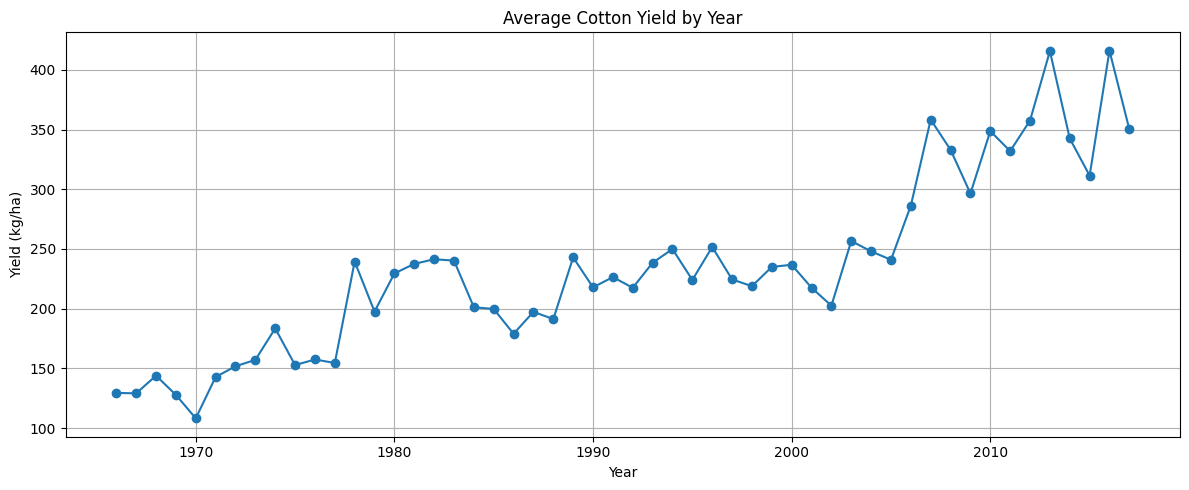

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter cotton records
cotton_data = data[
    data["Crop"].str.lower() == "cotton"
].copy()

# Calculate yearly statistics
cotton_yearly = (
    cotton_data.groupby("Year")["Yield_kg_per_ha"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

print("Cotton yield statistics for the last 20 years:")
print(cotton_yearly.tail(20).round(2).to_string(index=False))

# Plot average yield by year
plt.figure(figsize=(12, 5))

plt.plot(
    cotton_yearly["Year"],
    cotton_yearly["mean"],
    marker="o"
)

plt.title("Average Cotton Yield by Year")
plt.xlabel("Year")
plt.ylabel("Yield (kg/ha)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Select cotton records
cotton_train = train_data[
    train_data["Crop"].str.lower() == "cotton"
].copy()

cotton_test = test_data[
    test_data["Crop"].str.lower() == "cotton"
].copy()

# 2. Select useful candidate features
features = [
    "Year",
    "Area_ha",
    "State Name",
    "Dist Name"
]

numeric_features = ["Year", "Area_ha"]
categorical_features = ["State Name", "Dist Name"]

X_train = cotton_train[features]
y_train = cotton_train["Yield_kg_per_ha"]

X_test = cotton_test[features]
y_test = cotton_test["Yield_kg_per_ha"]

# 3. Preprocessing
preprocessor = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        numeric_features
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

# 4. Train a new model
cotton_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        ExtraTreesRegressor(
            n_estimators=400,
            min_samples_leaf=5,
            max_features=1.0,
            random_state=42,
            n_jobs=-1
        )
    )
])

cotton_model.fit(X_train, y_train)

# 5. Predict
predictions = np.maximum(
    cotton_model.predict(X_test),
    0
)

# 6. Evaluate
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("COTTON MODEL WITH TIME TREND")
print("-" * 40)
print(f"Training records: {len(X_train)}")
print(f"Testing records: {len(X_test)}")
print(f"MAE: {mae:.2f} kg/ha")
print(f"R2: {r2:.4f}")

# 7. Compare against your previous model
print("\nPREVIOUS EXTRA TREES MODEL")
print("MAE: 132.50 kg/ha")
print("R2: -0.0642")

COTTON MODEL WITH TIME TREND
----------------------------------------
Training records: 3031
Testing records: 825
MAE: 135.89 kg/ha
R2: -0.0967

PREVIOUS EXTRA TREES MODEL
MAE: 132.50 kg/ha
R2: -0.0642


In [ ]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Use the same cotton training and testing records
cotton_train = train_data[
    train_data["Crop"].str.lower() == "cotton"
].copy()

cotton_test = test_data[
    test_data["Crop"].str.lower() == "cotton"
].copy()

y_train = cotton_train["Yield_kg_per_ha"]
y_test = cotton_test["Yield_kg_per_ha"]

feature_sets = {
    "Year + Location": [
        "Year",
        "State Name",
        "Dist Name"
    ],

    "Year + Area + Location": [
        "Year",
        "Area_ha",
        "State Name",
        "Dist Name"
    ],

    "All Available Features": [
        "Year",
        "Area_ha",
        "State Name",
        "Dist Name",
        "Temperature_C",
        "Humidity_%",
        "pH",
        "Rainfall_mm",
        "Wind_Speed_m_s",
        "Solar_Radiation_MJ_m2_day"
    ]
}

results = []

for model_name, features in feature_sets.items():

    categorical = [
        col for col in features
        if col in ["State Name", "Dist Name"]
    ]

    numeric = [
        col for col in features
        if col not in categorical
    ]

    preprocessor = ColumnTransformer([
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical
        )
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            ExtraTreesRegressor(
                n_estimators=400,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(
        cotton_train[features],
        y_train
    )

    predictions = np.maximum(
        model.predict(cotton_test[features]),
        0
    )

    results.append({
        "Feature Set": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

print(
    pd.DataFrame(results)
    .round(4)
    .to_string(index=False)
)


           Feature Set      MAE      R2
       Year + Location 134.9408 -0.0841
Year + Area + Location 135.8865 -0.0967
All Available Features 136.0974 -0.0994


In [ ]:
# Inspect nutrient columns and their relationships with yield

nutrient_columns = [
    "N_req_kg_per_ha",
    "P_req_kg_per_ha",
    "K_req_kg_per_ha",
    "Yield_kg_per_ha"
]

print("Nutrient feature examples:")
print(data[nutrient_columns].head(15).to_string(index=False))

print("\nCorrelation matrix:")
print(data[nutrient_columns].corr().round(4))

print("\nNutrient-to-yield ratios:")

for col in [
    "N_req_kg_per_ha",
    "P_req_kg_per_ha",
    "K_req_kg_per_ha"
]:
    ratio = data[col] / data["Yield_kg_per_ha"].replace(0, float("nan"))

    print(f"\n{col}")
    print(ratio.describe().round(4))
    print("Unique ratios:", ratio.round(4).nunique())

Nutrient feature examples:
 N_req_kg_per_ha  P_req_kg_per_ha  K_req_kg_per_ha  Yield_kg_per_ha
         8.43975          4.05108          7.42698           337.59
        18.00009          8.00004         11.33339           666.67
         9.00000          5.00000          9.00000           500.00
        18.69275          8.97252         16.44962           747.71
        27.00000         12.00000         17.00000          1000.00
         5.19228          2.88460          5.19228           288.46
        21.03175         10.09524         18.50794           841.27
        19.28583          8.57148         12.14293           714.29
         8.07012          4.48340          8.07012           448.34
        17.78500          8.53680         15.65080           711.40
        22.99995         10.22220         14.48145           851.85
         7.90488          4.39160          7.90488           439.16
        20.71375          9.94260         18.22810           828.55
        35.64000     

In [ ]:
import numpy as np
import pandas as pd

nutrient_columns = [
    "N_req_kg_per_ha",
    "P_req_kg_per_ha",
    "K_req_kg_per_ha"
]

target = "Yield_kg_per_ha"

# Calculate nutrient-to-yield ratios
for col in nutrient_columns:
    data[f"{col}_ratio"] = (
        data[col] / data[target].replace(0, np.nan)
    )

# Examine the ratios for each crop
for crop in sorted(data["Crop"].unique()):

    crop_data = data[
        data["Crop"] == crop
    ]

    print(f"\n{'=' * 50}")
    print(f"CROP: {crop.upper()}")
    print("=" * 50)

    for col in nutrient_columns:

        ratio_col = f"{col}_ratio"

        print(f"\n{col}")
        print(
            crop_data[ratio_col]
            .describe()
            .round(5)
        )

        print(
            "Unique ratios:",
            crop_data[ratio_col]
            .round(5)
            .nunique()
        )


CROP: CHICKPEA

N_req_kg_per_ha
count    5457.000
mean        0.018
std         0.000
min         0.018
25%         0.018
50%         0.018
75%         0.018
max         0.018
Name: N_req_kg_per_ha_ratio, dtype: float64
Unique ratios: 1

P_req_kg_per_ha
count    5457.00
mean        0.01
std         0.00
min         0.01
25%         0.01
50%         0.01
75%         0.01
max         0.01
Name: P_req_kg_per_ha_ratio, dtype: float64
Unique ratios: 1

K_req_kg_per_ha
count    5457.000
mean        0.018
std         0.000
min         0.018
25%         0.018
50%         0.018
75%         0.018
max         0.018
Name: K_req_kg_per_ha_ratio, dtype: float64
Unique ratios: 1

CROP: COTTON

N_req_kg_per_ha
count    3856.000
mean        0.027
std         0.000
min         0.027
25%         0.027
50%         0.027
75%         0.027
max         0.027
Name: N_req_kg_per_ha_ratio, dtype: float64
Unique ratios: 1

P_req_kg_per_ha
count    3856.000
mean        0.012
std         0.000
min         0.012
2

In [ ]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Candidate features without nutrient columns
FEATURES = [
    "Crop",
    "Year",
    "State Name",
    "Dist Name",
    "Area_ha",
    "Temperature_C",
    "Humidity_%",
    "pH",
    "Rainfall_mm",
    "Wind_Speed_m_s",
    "Solar_Radiation_MJ_m2_day"
]

CATEGORICAL_FEATURES = [
    "Crop",
    "State Name",
    "Dist Name"
]

NUMERIC_FEATURES = [
    col for col in FEATURES
    if col not in CATEGORICAL_FEATURES
]

TARGET = "Yield_kg_per_ha"

# Prepare data
X_train = train_data[FEATURES].copy()
X_test = test_data[FEATURES].copy()

y_train = train_data[TARGET].copy()
y_test = test_data[TARGET].copy()

# Preprocessing
preprocessor = ColumnTransformer([
    (
        "categorical",
        Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="most_frequent")
            ),
            (
                "encoder",
                OneHotEncoder(handle_unknown="ignore")
            )
        ]),
        CATEGORICAL_FEATURES
    ),
    (
        "numeric",
        SimpleImputer(strategy="median"),
        NUMERIC_FEATURES
    )
])

# Model pipeline
final_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        ExtraTreesRegressor(
            n_estimators=400,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

# Train
final_model.fit(X_train, y_train)

# Predict
predictions = np.maximum(
    final_model.predict(X_test),
    0
)

# Evaluate
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("FINAL CANDIDATE MODEL RESULTS")
print("-" * 40)
print(f"Training records: {len(X_train)}")
print(f"Testing records: {len(X_test)}")
print(f"MAE: {mae:.2f} kg/ha")
print(f"RMSE: {rmse:.2f} kg/ha")
print(f"R²: {r2:.4f}")

# Evaluate each crop separately
results = []

for crop in sorted(test_data["Crop"].unique()):

    mask = (
        test_data["Crop"].to_numpy() == crop
    )

    actual_crop = y_test.to_numpy()[mask]
    predicted_crop = predictions[mask]

    results.append({
        "Crop": crop,
        "Records": int(mask.sum()),
        "MAE": mean_absolute_error(
            actual_crop,
            predicted_crop
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual_crop,
                predicted_crop
            )
        ),
        "R2": r2_score(
            actual_crop,
            predicted_crop
        )
    })

print("\nCROP-WISE RESULTS")

print(
    pd.DataFrame(results)
    .round(3)
    .to_string(index=False)
)


FINAL CANDIDATE MODEL RESULTS
----------------------------------------
Training records: 16500
Testing records: 4475
MAE: 481.72 kg/ha
RMSE: 809.12 kg/ha
R²: 0.7364

CROP-WISE RESULTS
    Crop  Records     MAE     RMSE     R2
chickpea     1201 228.475  318.090  0.395
  cotton      825 132.562  189.675 -0.065
   maize     1245 951.995 1337.801  0.526
    rice     1204 487.303  676.055  0.684


In [ ]:
import joblib

joblib.dump(
    final_model,
    "crop_yield_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import joblib
import numpy as np

loaded_model = joblib.load("crop_yield_model.joblib")

sample = test_data[FEATURES].iloc[[0]]

prediction = loaded_model.predict(sample)[0]

print("Crop:", sample["Crop"].iloc[0])
print("Predicted yield:", round(max(0, prediction), 2), "kg/ha")

Crop: cotton
Predicted yield: 219.23 kg/ha
